# 7주차. TSFM 심화 — LoRA 파인튜닝과 오염 검증

실행 환경: DGX Spark (GB10, aarch64) · `requirements_stage2.txt` · Python 3.11

In [1]:
import sys, time, platform, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import peft  # 없으면 fit(finetune_mode="lora")가 경고만 내고 전체 파인튜닝으로 바뀜
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

ROOT = Path("..").resolve()
sys.path.append(str(ROOT))
from src.backtest import rolling_backtest
from src.metrics import compute_naive_denominators, score_backtest
from src import bench_models as bm

# 서버(Ubuntu)에는 맑은 고딕이 없음 → 나눔고딕을 프로젝트 폴더에 받아 등록
FONT = ROOT / ".fonts/NanumGothic-Regular.ttf"
if not FONT.exists():
    FONT.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve("https://github.com/google/fonts/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf", FONT)
fm.fontManager.addfont(str(FONT))
plt.rcParams["font.family"] = fm.FontProperties(fname=FONT).get_name()
plt.rcParams["axes.unicode_minus"] = False

OUT = ROOT / "results/wk7"
OUT.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available(), "GPU가 안 보입니다 — 커널이 .venv(Python 3.11)인지 확인"
print(f"python {platform.python_version()} | torch {torch.__version__} (CUDA {torch.version.cuda}) | peft {peft.__version__}")
print(f"GPU: {torch.cuda.get_device_name(0)} | CPU 기본 스레드: {torch.get_num_threads()}")

data = bm.load_data()
weather, building_site = bm.load_weather(data)
print("데이터 shape:", data.shape)

/home/blueworks1/kimdongho/Self_Directed_Project/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


python 3.11.18 | torch 2.10.0+cu130 (CUDA 13.0) | peft 0.21.2
GPU: NVIDIA GB10 | CPU 기본 스레드: 20


/home/blueworks1/kimdongho/Self_Directed_Project/.venv/lib/python3.11/site-packages/torch/cuda/__init__.py:435: UserWarning: 
    Found GPU0 NVIDIA GB10 which is of cuda capability 12.1.
    Minimum and Maximum cuda capability supported by this version of PyTorch is
    (8.0) - (12.0)
    
  queued_call()


데이터 shape: (17544, 17)


## 과제 7-1. 5주차 Chronos-2 실험 GPU 재현 + CPU 대비 속도

In [2]:
CONTEXT, STEP_SIZE, N_WINDOWS = 1024, 168, 52  # 5주차 5-4와 동일
N_THREADS = 4                                   # 5주차 CPU 측정과 같은 스레드 수
torch.set_num_threads(N_THREADS)
DEVICES = ["cuda", "cpu"]

def chronos_fns(device, use_cov=False):
    return bm.make_chronos_fns(CONTEXT, use_cov, weather, building_site, pipeline=bm.get_chronos(device))

# 모델 로딩·첫 호출(CUDA 초기화)은 측정에서 제외
for d in DEVICES:
    model_fn, predict_fn = chronos_fns(d)
    predict_fn(model_fn(data.iloc[:CONTEXT]), 24)

rows = []
for horizon in [24, 168]:
    for use_cov in [False, True]:
        tag = "cov" if use_cov else "zero"
        wk5 = pd.read_csv(ROOT / f"results/wk5/chronos_{horizon}h_{tag}.csv", parse_dates=["timestamp"])
        denom = compute_naive_denominators(data, train_end=data.index.get_loc(wk5["timestamp"].min()), season=168)
        for d in DEVICES:
            t0 = time.perf_counter()
            res = rolling_backtest(data, *chronos_fns(d, use_cov), n_windows=N_WINDOWS, horizon=horizon,
                                   train_mode="expanding", step_size=STEP_SIZE)
            sec = time.perf_counter() - t0
            res.to_csv(OUT / f"chronos_{horizon}h_{tag}_{d}.csv", index=False, encoding="utf-8")
            rows.append({"horizon": horizon, "공변량": use_cov, "device": d,
                         "MASE_평균": score_backtest(res, denom)[1]["MASE_평균"],
                         "5주차 MASE(노트북 CPU)": score_backtest(wk5, denom)[1]["MASE_평균"],
                         "예측값 최대 차이": (res["y_pred"] - wk5["y_pred"]).abs().max(),
                         "백테스트 시간(s)": sec})
            print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in rows[-1].items()})

repro = pd.DataFrame(rows)
repro.to_csv(OUT / "gpu_reproduction.csv", index=False, encoding="utf-8")
speed_bt = repro.pivot_table(index=["horizon", "공변량"], columns="device", values="백테스트 시간(s)")
speed_bt["GPU 배속"] = speed_bt["cpu"] / speed_bt["cuda"]
print()
print(speed_bt.round(2).to_string())

{'horizon': 24, '공변량': False, 'device': 'cuda', 'MASE_평균': np.float64(0.3837), '5주차 MASE(노트북 CPU)': np.float64(0.3837), '예측값 최대 차이': np.float64(0.0021), '백테스트 시간(s)': 4.7452}
{'horizon': 24, '공변량': False, 'device': 'cpu', 'MASE_평균': np.float64(0.3837), '5주차 MASE(노트북 CPU)': np.float64(0.3837), '예측값 최대 차이': np.float64(0.0032), '백테스트 시간(s)': 47.1628}
{'horizon': 24, '공변량': True, 'device': 'cuda', 'MASE_평균': np.float64(0.3545), '5주차 MASE(노트북 CPU)': np.float64(0.3545), '예측값 최대 차이': np.float64(0.0018), '백테스트 시간(s)': 10.2614}
{'horizon': 24, '공변량': True, 'device': 'cpu', 'MASE_평균': np.float64(0.3545), '5주차 MASE(노트북 CPU)': np.float64(0.3545), '예측값 최대 차이': np.float64(0.0031), '백테스트 시간(s)': 69.6498}
{'horizon': 168, '공변량': False, 'device': 'cuda', 'MASE_평균': np.float64(0.81), '5주차 MASE(노트북 CPU)': np.float64(0.81), '예측값 최대 차이': np.float64(0.0019), '백테스트 시간(s)': 2.5805}
{'horizon': 168, '공변량': False, 'device': 'cpu', 'MASE_평균': np.float64(0.81), '5주차 MASE(노트북 CPU)': np.float64(0.81), '예측값 최대 차이': 

torch 스레드: 4 | 반복 6회 중 첫 회 제외 중앙값
device                cpu  cuda  노트북 cpu (5주차)  GPU 배속(서버 cpu 대비)
입력                                                               
건물 17개 배치           662.7  38.6            NaN               17.2
건물 1개 (5주차 5-6 조건)  134.1  11.6          341.8               11.5


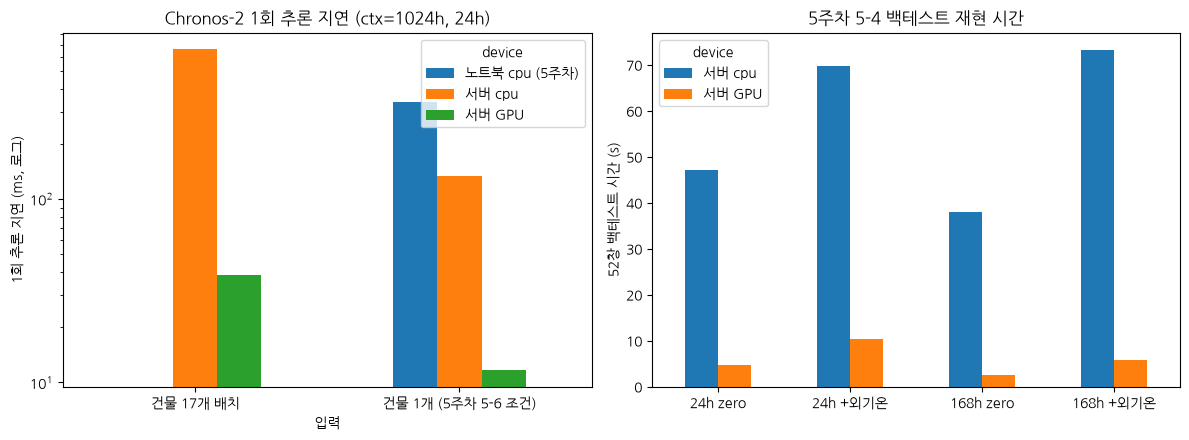

In [3]:
# 5주차 5-6과 같은 조건(건물 1개, 24h)에 17개 배치를 더해 1회 추론 지연 측정
def latency_ms(device, cols, n=6):
    model_fn, predict_fn = chronos_fns(device)
    state = model_fn(data[cols].iloc[:-24])
    times = []
    for _ in range(n):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        predict_fn(state, 24)
        torch.cuda.synchronize()
        times.append((time.perf_counter() - t0) * 1000)
    return float(np.median(times[1:]))  # 첫 호출(워밍업) 제외

inputs = {"건물 1개 (5주차 5-6 조건)": [data.columns[0]], "건물 17개 배치": list(data.columns)}
latency = pd.DataFrame([{"입력": k, "device": d, "median_ms": latency_ms(d, cols)}
                        for k, cols in inputs.items() for d in DEVICES]).pivot(index="입력", columns="device", values="median_ms")
wk5_cpu = pd.read_csv(ROOT / "results/wk5/cpu_timing.csv")
latency.loc["건물 1개 (5주차 5-6 조건)", "노트북 cpu (5주차)"] = wk5_cpu.loc[wk5_cpu["방식"].str.startswith("Chronos"), "median_ms"].item()
latency["GPU 배속(서버 cpu 대비)"] = latency["cpu"] / latency["cuda"]
latency.to_csv(OUT / "latency_cpu_vs_gpu.csv", encoding="utf-8")
print(f"torch 스레드: {N_THREADS} | 반복 6회 중 첫 회 제외 중앙값")
print(latency.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
latency[["노트북 cpu (5주차)", "cpu", "cuda"]].rename(columns={"cpu": "서버 cpu", "cuda": "서버 GPU"}).plot.bar(ax=axes[0], rot=0, logy=True)
axes[0].set_ylabel("1회 추론 지연 (ms, 로그)")
axes[0].set_title("Chronos-2 1회 추론 지연 (ctx=1024h, 24h)")
speed_bt[["cpu", "cuda"]].rename(columns={"cpu": "서버 cpu", "cuda": "서버 GPU"}).plot.bar(ax=axes[1], rot=0)
axes[1].set_xticklabels([f"{h}h {'+외기온' if c else 'zero'}" for h, c in speed_bt.index])
axes[1].set_xlabel("")
axes[1].set_ylabel("52창 백테스트 시간 (s)")
axes[1].set_title("5주차 5-4 백테스트 재현 시간")
plt.tight_layout()
plt.savefig(OUT / "cpu_vs_gpu_speed.png", dpi=110)
plt.show()

## 과제 7-3 · 7-4 · 7-5 — LoRA 파인튜닝 실행 (GPU)

- 파인튜닝은 **2016년으로 1회**, 평가는 5주차와 같은 **2017년 52창** (첫 origin 2017-01-08 → 누설 없음)
- 정상학습 = LEAD 이상 시점을 NaN으로 가림 / 오염학습 = 가리지 않음
- 예측은 `results/wk7/preds/*.parquet`, 학습 기록은 `results/wk7/fit_log.csv`에 쌓임. **이미 있는 실행은 건너뛰므로 끊겨도 다시 실행하면 이어서 진행**
- 채점·그래프는 `wk07_analysis.ipynb`(CPU)에서 합니다

In [4]:
from src import finetune as ft

mask = ft.load_anomaly_mask(data.columns)
PRED_DIR, CKPT_DIR = OUT / "preds", OUT / "ckpt"
PRED_DIR.mkdir(exist_ok=True)
FIT_LOG = OUT / "fit_log.csv"
base = bm.get_chronos("cuda")
print(f"LEAD 이상 시점 비율(2016, 17개 건물): {mask.to_numpy().mean():.2%}")

def backtest_2016(pipe):
    # 7-4 잔차 분석용: 라벨이 있는 2016년 전체를 24h 창으로 촘촘히 예측
    d16 = data.loc[ft.FT_START:ft.FT_END]
    return rolling_backtest(d16, *bm.make_chronos_fns(CONTEXT, pipeline=pipe), n_windows=(len(d16) - CONTEXT) // 24,
                            horizon=24, train_mode="expanding", step_size=24)

def run(name, train_df, horizon, seed, also_2016=False):
    # LoRA 1회 학습 → 5주차와 같은 52창 백테스트. 결과 파일이 있으면 건너뜀
    path = PRED_DIR / f"{name}.parquet"
    if path.exists():
        return
    model, info = ft.lora_fit(base, train_df, horizon, seed, CKPT_DIR / name)
    if also_2016:
        backtest_2016(model).to_parquet(PRED_DIR / f"{name}_2016.parquet", index=False)
    rolling_backtest(data, *bm.make_chronos_fns(CONTEXT, pipeline=model), n_windows=N_WINDOWS, horizon=horizon,
                     train_mode="expanding", step_size=STEP_SIZE).to_parquet(path, index=False)
    log = pd.DataFrame([{"run": name, "horizon": horizon, "seed": seed, "학습 시점 수": len(train_df), **info}])
    log.to_csv(FIT_LOG, mode="a", header=not FIT_LOG.exists(), index=False, encoding="utf-8")
    print(name, {k: round(v, 3) for k, v in info.items()})
    del model
    torch.cuda.empty_cache()

LEAD 이상 시점 비율(2016, 17개 건물): 2.15%


In [5]:
# 동작 확인: 20 step 1회 (결과 파일은 남기지 않음). 학습 비율·VRAM·소요 시간을 먼저 봅니다
_, smoke = ft.lora_fit(base, ft.finetune_frame(data, mask), 24, 0, CKPT_DIR / "smoke", num_steps=20)
print({k: round(v, 3) for k, v in smoke.items()})
print(f"1000 step 예상: 약 {smoke['학습 시간(s)'] / 20 * 1000 / 60:.0f}분/회 × 21회")

Could not estimate the number of tokens of the input, floating-point operations will not be computed


Step,Training Loss


{'학습 파라미터': 1206912, '전체 파라미터': 120684576, '학습 비율(%)': 1.0, '최대 VRAM(GB)': 4.181, '학습 시간(s)': 7.593}
1000 step 예상: 약 6분/회 × 21회


In [7]:
# 7-3: 정상학습 LoRA, 24h·168h × seed 3개 (24h 결과는 7-5의 100% 지점을 겸함)
for h in [24, 168]:
    for s in ft.SEEDS:
        run(f"clean_{h}h_f100_s{s}", ft.finetune_frame(data, mask), h, s, also_2016=(h == 24 and s == 0))

In [8]:
# 7-4: 오염학습 LoRA (이상 시점을 가리지 않음) + 비교 기준인 zero-shot 의 2016년 잔차
for s in ft.SEEDS:
    run(f"cont_24h_f100_s{s}", ft.finetune_frame(data), 24, s, also_2016=(s == 0))
if not (PRED_DIR / "zero_24h_2016.parquet").exists():
    backtest_2016(base).to_parquet(PRED_DIR / "zero_24h_2016.parquet", index=False)

In [9]:
# 7-5: 2016년의 마지막 1/5/10/50% 구간만으로 정상학습 (100%는 7-3에서 완료)
for f in ft.FRACTIONS[:-1]:
    for s in ft.SEEDS:
        run(f"clean_24h_f{round(f * 100):03d}_s{s}", ft.finetune_frame(data, mask, f), 24, s)

fit_log = pd.read_csv(FIT_LOG)
print(fit_log[["run", "학습 시점 수", "학습 비율(%)", "최대 VRAM(GB)", "학습 시간(s)"]].round(3).to_string(index=False))
print()
print("판정 기준: 학습 비율 0.1~1%, VRAM 8GB 이내")

               run  학습 시점 수  학습 비율(%)  최대 VRAM(GB)  학습 시간(s)
 clean_24h_f100_s0     8784       1.0        4.682   249.353
 clean_24h_f100_s1     8784       1.0        4.666   250.445
 clean_24h_f100_s2     8784       1.0        4.666   251.233
clean_168h_f100_s0     8784       1.0        5.069   286.681
clean_168h_f100_s1     8784       1.0        5.072   288.326
clean_168h_f100_s2     8784       1.0        5.070   287.143
  cont_24h_f100_s0     8784       1.0        4.666   250.700
  cont_24h_f100_s1     8784       1.0        4.666   251.121
  cont_24h_f100_s2     8784       1.0        4.667   252.672
 clean_24h_f001_s0       88       1.0        2.058    46.459
 clean_24h_f001_s1       88       1.0        2.057    47.844
 clean_24h_f001_s2       88       1.0        2.057    48.041
 clean_24h_f005_s0      439       1.0        3.060   107.218
 clean_24h_f005_s1      439       1.0        3.054   107.392
 clean_24h_f005_s2      439       1.0        3.060   105.271
 clean_24h_f010_s0      